# Regressió polinòmica multivariable
--------------------

En aquest Notebook volem estudiar el preu de les vivendes de Brooklyn en funció de dues o tres variables i també en funció de regressions polinòmiques.

El mateix que l'anterior però utilitzant PipeLines

In [6]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.pipeline import Pipeline
#from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import drive

drive.mount('/content/drive')
#path = '/content/drive/'
os.chdir('/content/drive/MyDrive/Colab Notebooks/M0572-SistemesAprenentatgeAutomatic_2526/02_models_supervisats/')
os.getcwd()

# dataset extret de
# https://www.kaggle.com/datasets/ciphernine/brooklyn-real-estate-listings
df = pd.read_csv('dataset/brooklyn_real_estate.csv')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Unnamed: 0,price,bedrooms,bathrooms,sqft,neighborhood,status,address
0,1,4100000.0,4,5,2940.0,Park Slope,sold,"336A 4th St, Brooklyn, NY 11215"
1,2,1020000.0,3,1,NaN,Park Slope,sold,"411 15th St #K, Brooklyn, NY 11215"
2,3,45000.0,0,1,NaN,Park Slope,sold,"65 Saint Johns Pl #D, Brooklyn, NY 11217"
3,4,45000.0,0,1,NaN,Park Slope,sold,"65 Saint Johns Pl #E, Brooklyn, NY 11217"
4,5,908000.0,0,1,1066.0,Park Slope,sold,"397 1st St #4R, Brooklyn, NY 11215"


## Exemple amb 2 variables (els metres quadrats i el nº de banys)

In [7]:
# En aqeust exemple intentarem estimar el preu dels habitatges en funció del número de banys, i metres quadrats (peus quadrats)
data = df[['price','bathrooms','sqft']].dropna()

# Mostrem una quantitat de dades
data.head()
#print(df.sample(n=15))

,price,bathrooms,sqft
0,4100000.0,5,2940.0
4,908000.0,1,1066.0
6,2600000.0,4,3600.0
7,4050000.0,4,3600.0
8,2400000.0,3,1428.0


In [9]:
X = data[["bathrooms", "sqft"]]
y = data["price"]


#Fem el train test split amb el 80-20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

display(data.head())


,price,bathrooms,sqft
0,4100000.0,5,2940.0
4,908000.0,1,1066.0
6,2600000.0,4,3600.0
7,4050000.0,4,3600.0
8,2400000.0,3,1428.0


In [11]:

#definim el grau del nostre polinomi, amb el grau que volem. En aquest cas 2
grau = 2

model = Pipeline([
        ("polinomi", PolynomialFeatures(degree=grau, include_bias=False)),
        #("escalat", StandardScaler()),
        ("regressio", LinearRegression()),
])
# Configuro el paràmetre include_bias=False perquè LinearRegression ja ajusta el terme constant amb intercept_

model.fit(X_train, y_train)

# Els dobles claudàtors mantenen el format de taula amb una sola fila.
primera_fila = X.iloc[[0]]


polinomi = model.named_steps["polinomi"]
noms_termes = polinomi.get_feature_names_out()
fila_transformada = polinomi.transform(primera_fila)[0]

print("Valors originals")
display(primera_fila)

print("Termes polinòmics abans de l'escalat")
display(pd.Series(fila_transformada, index=noms_termes, name="valor"))

# La forma del polinomi hauria de ser [1, a, b, a^2, ab, b^2]
# Recuperem el transformador que ja ha ajustat el Pipeline.
#poly_x_values = model_polinomic.named_steps["polinomi"]
#print(f'Valors inicials {x_values[0]}\nMapejats(Polinomi) {poly_x_values[0]}')

# grau 2 [1, a=5, b=2940, a^2=25, a·b=5*2940=14700, b^2=8643600]
# grau 3 [1, a=5, b=2940, a^2=25, a·b=5*2940=14700, b^2=8643600, b·a^2=73500, a·b^2=43218000, a^3=125, b^3=25412184000]





Valors originals


,bathrooms,sqft
0,5,2940.0


Termes polinòmics abans de l'escalat


,valor
bathrooms,5.0
sqft,2940.0
bathrooms^2,25.0
bathrooms sqft,14700.0
sqft^2,8643600.0


In [13]:
graus = range(1, 8)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
files = []

for grau in graus:
    puntuacions = cross_validate(
        Pipeline([
            ("polinomi", PolynomialFeatures(degree=grau, include_bias=False)),
            #("escalat", StandardScaler()),
            ("regressio", LinearRegression()),
        ]),
        X_train,
        y_train,
        cv=kf,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
        return_train_score=True,
    )

    files.append({
        "grau": grau,
        "rmse_train": -puntuacions["train_rmse"].mean(),
        "rmse_validacio": -puntuacions["test_rmse"].mean(),
        "r2_validacio": puntuacions["test_r2"].mean(),
    })

resultats = pd.DataFrame(files).set_index("grau")
display(resultats.round(3))


,rmse_train,rmse_validacio,r2_validacio
grau,,,
1,1231316.068,2.411628e+06,-7.079
2,1118169.775,5.028514e+07,-9156.731
3,1145836.075,2.380788e+07,-1858.832
4,1252480.952,1.907794e+06,-1.849
5,1255084.608,2.437081e+06,-5.797
6,1259203.587,4.783489e+06,-22.290
7,1259214.924,1.330162e+07,-214.462


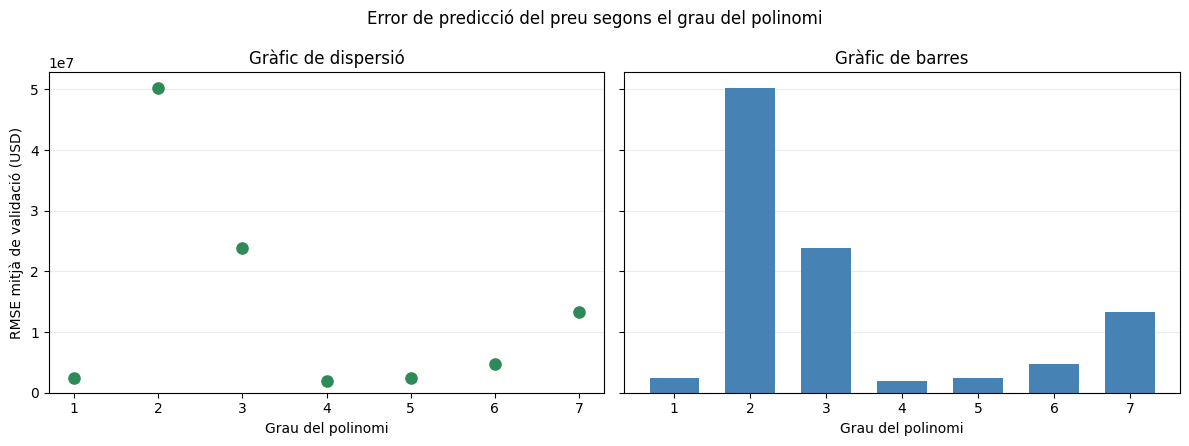

In [15]:
# Executa aquesta cel·la després de crear el DataFrame `resultats`.
graus = resultats.index
errors = resultats["rmse_validacio"]

fig, (ax_scatter, ax_bar) = plt.subplots(
    1, 2, figsize=(12, 4.5), sharey=True
)

# Gràfic de dispersió
ax_scatter.scatter(graus, errors, color="seagreen", s=65, zorder=3)
ax_scatter.set_title("Gràfic de dispersió")
ax_scatter.set_ylabel("RMSE mitjà de validació (USD)")

# Gràfic de barres
ax_bar.bar(graus, errors, color="steelblue", width=0.65)
ax_bar.set_title("Gràfic de barres")

for ax in (ax_scatter, ax_bar):
    ax.set_xlabel("Grau del polinomi")
    ax.set_xticks(graus)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

ax_scatter.set_ylim(bottom=0)

fig.suptitle("Error de predicció del preu segons el grau del polinomi")
fig.tight_layout()
plt.show()